# 02 – Exploratory Data Analysis

Explores the processed outputs of `01_data_collection.ipynb`:

| Table | File | Grain |
|---|---|---|
| `players` | `data/processed/top300_players.csv` | one row per ladder player |
| `matches` | `data/processed/player_matches.csv` | one row per (player, match) |

## Setup

In [26]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

sys.path.append(str(Path.cwd().parent))  # make `src` importable from notebooks/
from src.config import PROCESSED_DIR

pd.set_option("display.max_columns", None)

## 1. Load Data
Both CSVs were saved with the pandas index as the first column, so `index_col=0` drops it back into the index.

In [16]:
players = pd.read_csv(PROCESSED_DIR / "top300_players.csv", index_col=0)
matches = pd.read_csv(
    PROCESSED_DIR / "player_matches.csv",
    index_col=0,
    parse_dates=["gameCreation"],
    dtype={"patch": str},  # keep e.g. "16.10" from becoming 16.1
)

print(f"players: {players.shape} | matches: {matches.shape}")
players.head()

players: (300, 14) | matches: (30000, 33)


,ladder_rank,puuid,leaguePoints,rank,wins,losses,veteran,inactive,freshBlood,hotStreak,games,win_rate,riotIdGameName,riotIdTagline
0,1,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,4041,I,358,245,True,False,False,False,603,0.593698,C9 Loki,kr3
1,2,8WfFV8TPkd6DIaajOHARJAJR8BJF8U9sTmFRzt4SfhmSe7...,4013,I,558,352,True,False,False,True,910,0.613187,never type,1998
2,3,lmPjvRxc2s1Ha9Wbb8y6SkcbvZUF1vN86QNM_Ib4cOQMRt...,3523,I,636,504,True,False,False,True,1140,0.557895,Lobby Admin,FIGHT
3,4,XwiJ6fkuW_8DC9PDNvlKYAFlgm4e6j952DE0TqJWWt9Rxl...,3228,I,698,545,True,False,False,False,1243,0.561545,Davemon,NA1
4,5,i627oHfp0rlM_VbmJMFze12mD6UYaiao9Hl6XTmYHKrSON...,3217,I,497,421,True,False,False,False,918,0.541394,LFT Sheiden,PHL1


In [13]:
matches.head()

,matchId,puuid,gameCreation,gameDuration_min,gameVersion,patch,riotIdGameName,riotIdTagline,championName,teamPosition,teamId,win,kills,deaths,assists,totalMinionsKilled,neutralMinionsKilled,goldEarned,totalDamageDealtToChampions,damageDealtToObjectives,visionScore,wardsPlaced,wardsKilled,champLevel,timeCCingOthers,firstBloodKill,turretKills,gameEndedInEarlySurrender,cs,cs_per_min,gold_per_min,kda,is_remake
0,NA1_5659998027,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-14 03:55:52.729,17.866667,16.20.824.8524,16.20,C9 Loki,kr3,Akali,MIDDLE,200,False,3,4,1,163,0,6874,7993,1773,18,5,3,12,3,False,0,False,163,9.123134,384.738806,1.000000,False
1,NA1_5659953897,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-14 03:01:47.670,32.816667,16.20.824.8524,16.20,C9 Loki,kr3,Pyke,UTILITY,200,False,5,9,16,32,0,10206,14722,821,118,46,15,13,33,False,0,False,32,0.975114,311.000508,2.333333,False
2,NA1_5659936919,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-14 02:34:36.093,23.583333,16.20.824.8524,16.20,C9 Loki,kr3,Lissandra,MIDDLE,100,True,2,5,10,218,0,10148,15105,4909,23,11,2,15,32,False,0,False,218,9.243816,430.303887,2.400000,False
3,NA1_5659295272,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-13 01:39:45.362,31.933333,16.20.824.8524,16.20,C9 Loki,kr3,Ahri,MIDDLE,200,False,5,7,8,267,0,13145,26669,5570,59,13,16,16,25,False,1,False,267,8.361169,411.638831,1.857143,False
4,NA1_5659128611,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-12 21:38:46.451,26.216667,16.20.824.8524,16.20,C9 Loki,kr3,Akali,MIDDLE,200,True,19,3,7,232,4,16496,30399,15322,23,6,3,17,4,True,3,False,236,9.001907,629.218055,8.666667,False


## 2. Null Values – `Matches`
Count and percentage of missing values in every column of the matches table.

In [14]:
matches_nulls = pd.DataFrame({
    "dtype": matches.dtypes,
    "null_count": matches.isna().sum(),
    "null_pct": (matches.isna().mean() * 100).round(2),
})

print(f"Total nulls: {matches_nulls.null_count.sum()} | columns with nulls: {(matches_nulls.null_count > 0).sum()}/{len(matches_nulls)}")
matches_nulls
matches_nulls[matches_nulls["null_count"] > 0]

Total nulls: 3 | columns with nulls: 1/33


,dtype,null_count,null_pct
teamPosition,object,3,0.01


There are 3 rows containing null values for the column 'teamPosition'. We can look at these specific rows to see what's going on.

In [19]:
matches[matches['teamPosition'].isna()]

,matchId,puuid,gameCreation,gameDuration_min,gameVersion,patch,riotIdGameName,riotIdTagline,championName,teamPosition,teamId,win,kills,deaths,assists,totalMinionsKilled,neutralMinionsKilled,goldEarned,totalDamageDealtToChampions,damageDealtToObjectives,visionScore,wardsPlaced,wardsKilled,champLevel,timeCCingOthers,firstBloodKill,turretKills,gameEndedInEarlySurrender,cs,cs_per_min,gold_per_min,kda,is_remake
6859,NA1_5624278048,xGwmbjg6AQ_yUMtlxE07wPYlEv4yJjhFeZpp1EoPCqJA2G...,2026-08-19 04:16:12.621,2.066667,16.16.804.9184,16.16,twtv kaidojungle,IWNL,Seraphine,NaN,200,False,0,0,0,0,0,622,0,0,0,0,0,1,0,False,0,True,0,0.0,300.967742,0.0,True
11778,NA1_5647543712,Y98pwQ3M4rbyvTn7BKJboT6RNvreqFxjGhQVI5yymuo66h...,2026-09-23 17:23:55.198,3.733333,16.19.820.7193,16.19,GLIDE GLIDE,SMURF,Jinx,NaN,200,False,0,0,0,0,0,826,0,0,0,0,0,1,0,False,0,False,0,0.0,221.250000,0.0,True
29811,NA1_5660269852,aGuNpPXy5i8HJpZsxykNN12EfhJJJcTocRdYs83q1G5kC-...,2026-10-14 19:57:19.534,3.400000,16.20.824.8524,16.20,SHAK,HAHA,Alistar,NaN,100,False,0,1,0,0,0,826,0,0,0,0,0,1,0,False,0,False,0,0.0,242.941176,0.0,True


These 3 games look to be remakes, which we are going to filter out anyways in a later step, so we can effectively ignore these.

In [20]:
matches = matches[matches['is_remake'] == False]

In [21]:
matches.shape

(29719, 33)

So remakes account for 281 of the 30000 games, or around 1% of the games.

## 3. Unique Matches

Since the challenger league is entirely made up of the top 300 players, it is very likely that a lot of the observations in `Matches` are going to share the same match. We can check the number of uniques matches by counting the distinct count of matchIDs.

In [24]:
matches['matchId'].nunique()

14230

Under half of the observations in `matches` are from unique games. This shouldn't matter for the most part when studying more of the player level metrics like kills per death, but will bias game wide statistics like game length. So just for the purpose of briefly exploring game duration for now, we will create a deduplicated copy of `matches`.

In [25]:
umatches = matches.drop_duplicates('matchId')
umatches.shape

(14230, 33)

## 4. Distribution of game length

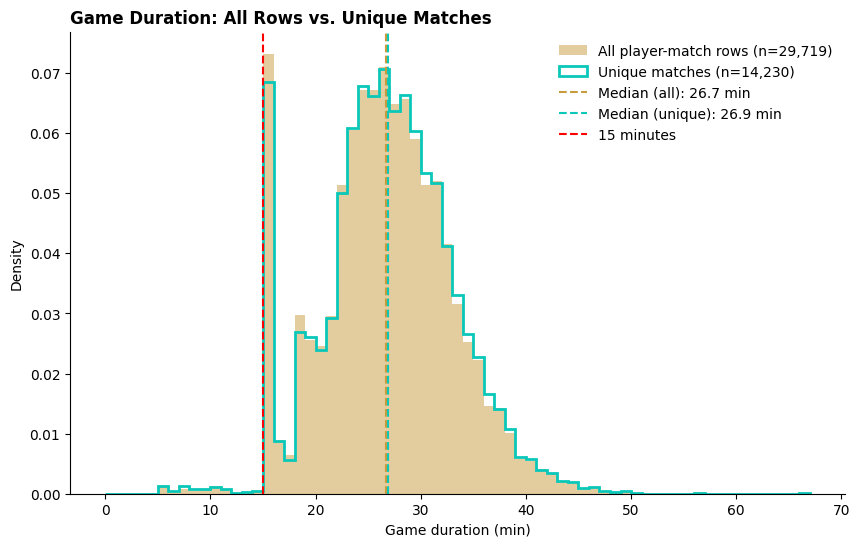

,all_rows,unique_matches
count,29719.00,14230.00
mean,26.68,26.82
std,6.28,6.30
min,5.00,5.00
25%,22.88,23.05
50%,26.72,26.85
75%,30.73,30.90
max,66.53,66.53


In [41]:
GOLD, BLUE = "#C89B3C", "#0AC8B9"
bins = np.arange(0, matches["gameDuration_min"].max() + 1, 1)  # 1-minute bins, shared by both

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(matches["gameDuration_min"], bins=bins, density=True, color=GOLD, alpha=0.5,
        label=f"All player-match rows (n={len(matches):,})")
ax.hist(umatches["gameDuration_min"], bins=bins, density=True, histtype="step", lw=2, color=BLUE,
        label=f"Unique matches (n={len(umatches):,})")

for data, color, name in [(matches, GOLD, "all"), (umatches, BLUE, "unique")]:
    med = data["gameDuration_min"].median()
    ax.axvline(med, color=color, ls="--", lw=1.5, label=f"Median ({name}): {med:.1f} min")
ax.axvline(15, color= 'red', ls="--", lw=1.5, label= "15 minutes")
ax.set_title("Game Duration: All Rows vs. Unique Matches", loc="left", fontweight="bold")
ax.set_xlabel("Game duration (min)")
ax.set_ylabel("Density")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

pd.DataFrame({
    "all_rows": matches["gameDuration_min"].describe(),
    "unique_matches": umatches["gameDuration_min"].describe(),
}).round(2)


The distribution of game duration across the unique matches and the entire dataset look to be approximately the same, with the mean marginally higher by about 1 second across the unique matches. The most apparent difference between the 2 distributions is the difference in the spike at around the 15 minute mark.

The overall distrubution looks to be bimodal, with peaks at 15 minutes and around the mean at 27 minutes. The most likely reason for such a high frequency of 15 minute games is due to forfeits, where teams have the option to surrender early up to the 15 minute mark.

In [47]:
counts_unique, _ = np.histogram(umatches["gameDuration_min"], bins=bins)

bin_freqs = pd.DataFrame({
    "bin": pd.IntervalIndex.from_breaks(bins, closed="left"),  # [a, b); numpy also includes the top edge in the last bin
    "count": counts_unique,
    "pct": counts_unique / counts_unique.sum() * 100,
})
bin_freqs.nlargest(5, "pct")


,bin,count,pct
26,"[26.0, 27.0)",1005,7.062544
15,"[15.0, 16.0)",974,6.844694
24,"[24.0, 25.0)",966,6.788475
28,"[28.0, 29.0)",944,6.633872
25,"[25.0, 26.0)",941,6.612790


Most matches ended due to early surrender generally take a few seconds longer than 15 minutes as the surrender votes need to go through, essentially padding a few seconds to the match. This is likely the reason for such a large concentration of games between 15 and 16 minutes.